# GPU-Based Sobel Edge Detection

This notebook evaluates Sobel edge detection using **NumPy on the CPU** and **Numba CUDA on an NVIDIA GPU**.

The experiments cover:
- Correctness using a real grayscale image.
- CPU and GPU performance across different image resolutions.
- GPU thread-block configuration.
- A shared-memory kernel experiment.
- GPU utilization, memory usage, and power monitoring.

Synthetic images are used only for repeatable performance benchmarks. A real image is used for the visual correctness demonstration.


## 1. GPU Environment and Libraries

The experiments use Google Colab with an NVIDIA Tesla T4 GPU.

Numba CUDA is used to implement the GPU-based Gaussian blur kernel. NumPy and Numba are used for the CPU implementation, while Pandas and Matplotlib are used for result analysis and visualization.

The CUDA environment and GPU availability are verified before executing the experiments.


In [1]:
!pip -q install "numba-cuda[cu13]"

!nvidia-smi

import os
import time
import math
import threading
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numba import cuda, float32
from IPython.display import display

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("CUDA available:", cuda.is_available())

if not cuda.is_available():
    raise RuntimeError("CUDA GPU is not available. Select a GPU runtime in Colab.")

print("GPU:", cuda.get_current_device().name)

Sat Nov 14 07:59:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. CPU Implementation

The Sobel operator calculates horizontal and vertical intensity gradients. The magnitude of these gradients represents edge strength.

The border pixels are kept at zero in both implementations.

In [2]:
def sobel_cpu(image):
    img = image.astype(np.float32)
    height, width = img.shape

    gx = np.zeros((height, width), dtype=np.float32)
    gy = np.zeros((height, width), dtype=np.float32)

    gx[1:-1, 1:-1] = (
        -img[:-2, :-2] + img[:-2, 2:]
        - 2 * img[1:-1, :-2] + 2 * img[1:-1, 2:]
        - img[2:, :-2] + img[2:, 2:]
    )

    gy[1:-1, 1:-1] = (
        -img[:-2, :-2] - 2 * img[:-2, 1:-1] - img[:-2, 2:]
        + img[2:, :-2] + 2 * img[2:, 1:-1] + img[2:, 2:]
    )

    return np.sqrt(gx * gx + gy * gy)

## 3. GPU Implementation

Each CUDA thread calculates the Sobel output for one pixel. The input image is transferred to GPU memory, processed by the kernel, and copied back to CPU memory.

In [3]:
@cuda.jit
def sobel_kernel(img, edges):
    x, y = cuda.grid(2)
    height, width = img.shape

    if x > 0 and x < width - 1 and y > 0 and y < height - 1:
        gx = (
            -img[y-1, x-1] + img[y-1, x+1]
            - 2 * img[y, x-1] + 2 * img[y, x+1]
            - img[y+1, x-1] + img[y+1, x+1]
        )

        gy = (
            -img[y-1, x-1] - 2 * img[y-1, x] - img[y-1, x+1]
            + img[y+1, x-1] + 2 * img[y+1, x] + img[y+1, x+1]
        )

        edges[y, x] = math.sqrt(gx * gx + gy * gy)
    else:
        edges[y, x] = 0.0


def sobel_gpu(image, threads_per_block=(16, 16)):
    img = image.astype(np.float32)
    height, width = img.shape

    d_img = cuda.to_device(img)
    d_edges = cuda.device_array((height, width), dtype=np.float32)

    blocks_per_grid = (
        (width + threads_per_block[0] - 1) // threads_per_block[0],
        (height + threads_per_block[1] - 1) // threads_per_block[1]
    )

    sobel_kernel[blocks_per_grid, threads_per_block](d_img, d_edges)
    cuda.synchronize()

    return d_edges.copy_to_host()

## 4. Correctness Demonstration Using a Real Image

A real grayscale photograph is used to demonstrate the output of both implementations. The CPU and GPU results are compared numerically and visually.

In [4]:
!pip -q install scikit-image

# Load a real grayscale image
from skimage import data

real_image = data.camera()

cpu_real_edges = sobel_cpu(real_image)
gpu_real_edges = sobel_gpu(real_image)

max_difference = np.max(np.abs(cpu_real_edges - gpu_real_edges))
outputs_match = np.allclose(
    cpu_real_edges, gpu_real_edges, rtol=1e-5, atol=1e-4
)

print("Image shape:", real_image.shape)
print("Maximum absolute difference:", max_difference)
print("CPU and GPU outputs match:", outputs_match)

if not outputs_match:
    raise AssertionError("CPU and GPU Sobel outputs do not match.")

Image shape: (512, 512)
Maximum absolute difference: 0.0
CPU and GPU outputs match: True


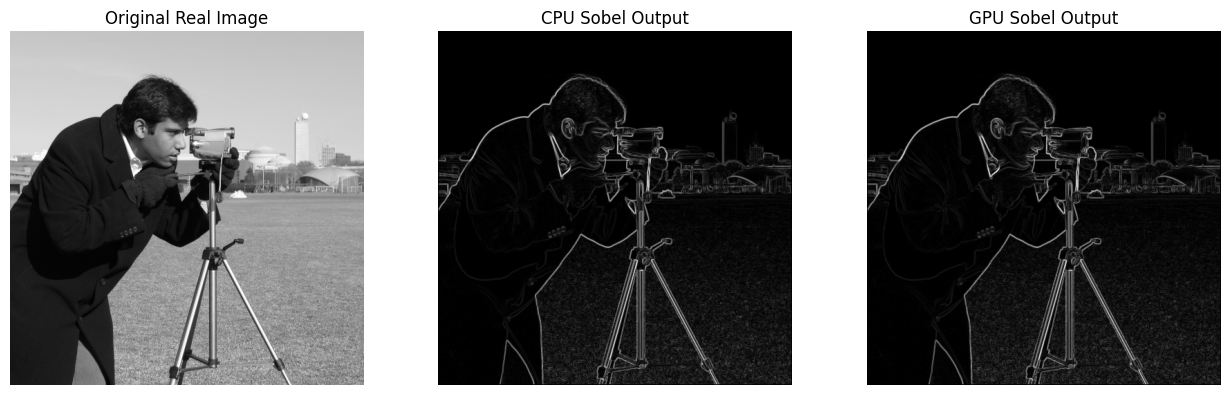

In [5]:
plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.imshow(real_image, cmap="gray")
plt.title("Original Real Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cpu_real_edges, cmap="gray")
plt.title("CPU Sobel Output")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gpu_real_edges, cmap="gray")
plt.title("GPU Sobel Output")
plt.axis("off")

plt.tight_layout()
os.makedirs("results/figures", exist_ok=True)
plt.savefig("results/figures/sobel_real_image_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

## 5. Performance Across Different Image Resolutions

Repeatable synthetic grayscale images are generated at four resolutions:

- 256 × 256
- 512 × 512
- 1024 × 1024
- 2048 × 2048

For each resolution, the notebook measures:

- CPU execution time.
- GPU kernel execution time (excluding transfers).
- GPU end-to-end execution time (including input transfer, output allocation, kernel execution, and output transfer).

The same image is used for the CPU and GPU measurements at each resolution.

In [6]:
resolutions = [256, 512, 1024, 2048]
results = []
correctness_results = []

for size in resolutions:
    print(f"Running {size} x {size} ...")

    rng = np.random.default_rng(42)
    test_image = rng.integers(
        0, 256, size=(size, size), dtype=np.uint8
    )
    test_float = test_image.astype(np.float32)

    # CPU timing
    sobel_cpu(test_image)  # warm-up
    cpu_times = []

    for _ in range(20):
        start = time.perf_counter()
        cpu_result = sobel_cpu(test_image)
        cpu_times.append(time.perf_counter() - start)

    cpu_avg_ms = np.mean(cpu_times) * 1000

    # GPU setup
    threads = (16, 16)
    blocks = (
        (size + threads[0] - 1) // threads[0],
        (size + threads[1] - 1) // threads[1]
    )
    d_input = cuda.to_device(test_float)
    d_output = cuda.device_array((size, size), dtype=np.float32)

    # GPU kernel timing
    sobel_kernel[blocks, threads](d_input, d_output)  # warm-up
    cuda.synchronize()

    start_event = cuda.event()
    end_event = cuda.event()
    start_event.record()

    for _ in range(50):
        sobel_kernel[blocks, threads](d_input, d_output)

    end_event.record()
    end_event.synchronize()
    gpu_kernel_avg_ms = cuda.event_elapsed_time(start_event, end_event) / 50

    # GPU end-to-end timing
    total_times = []

    for _ in range(10):
        cuda.synchronize()
        start = time.perf_counter()

        d_in = cuda.to_device(test_float)
        d_out = cuda.device_array((size, size), dtype=np.float32)
        sobel_kernel[blocks, threads](d_in, d_out)
        gpu_result = d_out.copy_to_host()

        cuda.synchronize()
        total_times.append(time.perf_counter() - start)

    gpu_total_avg_ms = np.mean(total_times) * 1000

    kernel_speedup = cpu_avg_ms / gpu_kernel_avg_ms
    end_to_end_speedup = cpu_avg_ms / gpu_total_avg_ms

    correctness_results.append({
        "Resolution": f"{size}x{size}",
        "Outputs Match": np.allclose(
            cpu_result, gpu_result, rtol=1e-5, atol=1e-4
        ),
        "Maximum Difference": float(np.max(np.abs(cpu_result - gpu_result)))
    })

    results.append({
        "Resolution": f"{size}x{size}",
        "CPU (ms)": cpu_avg_ms,
        "GPU Kernel (ms)": gpu_kernel_avg_ms,
        "GPU End-to-End (ms)": gpu_total_avg_ms,
        "Kernel Speedup": kernel_speedup,
        "End-to-End Speedup": end_to_end_speedup
    })

results_df = pd.DataFrame(results)
correctness_df = pd.DataFrame(correctness_results)

print("Performance comparison:")
display(results_df.round(4))

print("Correctness verification:")
display(correctness_df)

Running 256 x 256 ...
Running 512 x 512 ...
Running 1024 x 1024 ...
Running 2048 x 2048 ...
Performance comparison:


,Resolution,CPU (ms),GPU Kernel (ms),GPU End-to-End (ms),Kernel Speedup,End-to-End Speedup
0,256x256,1.0820,0.0666,0.9631,16.2442,1.1235
1,512x512,4.4035,0.2100,1.7499,20.9660,2.5164
2,1024x1024,23.9227,0.8161,5.1526,29.3124,4.6428
3,2048x2048,118.4407,3.2279,11.6378,36.6933,10.1772


Correctness verification:


,Resolution,Outputs Match,Maximum Difference
0,256x256,True,0.0
1,512x512,True,0.0
2,1024x1024,True,0.0
3,2048x2048,True,0.0


## 6. GPU Memory Transfer Performance

GPU applications require data to be transferred between CPU memory and GPU memory.

This experiment measures the two transfer operations separately:

- **Host-to-Device (H2D):** Transfer of the input image from CPU memory to GPU memory.
- **Device-to-Host (D2H):** Transfer of the processed output from GPU memory back to CPU memory.

Both measurements are performed using a 2048 × 2048 image. The average transfer time is calculated over multiple runs.

These measurements help understand the contribution of data transfer overhead to overall GPU execution time.

In [7]:

# Prepare a repeatable 2048 x 2048 image
rng = np.random.default_rng(42)

transfer_image = rng.integers(
    0, 256, size=(2048, 2048), dtype=np.uint8
).astype(np.float32)

transfer_runs = 100

# Allocate GPU memory before measuring transfers
d_transfer_input = cuda.device_array(
    transfer_image.shape, dtype=np.float32
)

d_transfer_output = cuda.device_array(
    transfer_image.shape, dtype=np.float32
)

# Warm-up transfers
d_transfer_input.copy_to_device(transfer_image)
d_transfer_output.copy_to_host()
cuda.synchronize()

# Measure Host-to-Device transfer
h2d_times = []

for _ in range(transfer_runs):
    cuda.synchronize()
    start = time.perf_counter()

    d_transfer_input.copy_to_device(transfer_image)

    cuda.synchronize()
    h2d_times.append(time.perf_counter() - start)

h2d_avg_ms = np.mean(h2d_times) * 1000

# Measure Device-to-Host transfer
d2h_times = []

for _ in range(transfer_runs):
    cuda.synchronize()
    start = time.perf_counter()

    output_cpu = d_transfer_output.copy_to_host()

    cuda.synchronize()
    d2h_times.append(time.perf_counter() - start)

d2h_avg_ms = np.mean(d2h_times) * 1000

print("GPU Memory Transfer Results")
print("---------------------------")
print("Image resolution: 2048 x 2048")
print("Average H2D transfer time:", round(h2d_avg_ms, 5), "ms")
print("Average D2H transfer time:", round(d2h_avg_ms, 5), "ms")


GPU Memory Transfer Results
---------------------------
Image resolution: 2048 x 2048
Average H2D transfer time: 9.5454 ms
Average D2H transfer time: 9.79993 ms


## 7. Thread-Block Configuration Comparison

The GPU kernel is evaluated using 8 × 8, 16 × 16, and 32 × 32 threads per block. The same real image and kernel are used for all configurations.

In [8]:
thread_configs = [(8, 8), (16, 16), (32, 32)]
block_results = []

real_image_float = real_image.astype(np.float32)
d_real_image = cuda.to_device(real_image_float)

for threads in thread_configs:
    blocks = (
        (real_image.shape[1] + threads[0] - 1) // threads[0],
        (real_image.shape[0] + threads[1] - 1) // threads[1]
    )
    d_output = cuda.device_array(real_image.shape, dtype=np.float32)

    sobel_kernel[blocks, threads](d_real_image, d_output)  # warm-up
    cuda.synchronize()

    start_event = cuda.event()
    end_event = cuda.event()
    start_event.record()

    for _ in range(100):
        sobel_kernel[blocks, threads](d_real_image, d_output)

    end_event.record()
    end_event.synchronize()

    avg_time_ms = cuda.event_elapsed_time(start_event, end_event) / 100
    output = d_output.copy_to_host()

    block_results.append({
        "Threads per Block": f"{threads[0]}x{threads[1]}",
        "Total Threads": threads[0] * threads[1],
        "GPU Kernel Time (ms)": avg_time_ms,
        "Outputs Match": np.allclose(
            cpu_real_edges, output, rtol=1e-5, atol=1e-4
        )
    })

block_df = pd.DataFrame(block_results)
display(block_df.round(5))

,Threads per Block,Total Threads,GPU Kernel Time (ms),Outputs Match
0,8x8,64,0.21389,True
1,16x16,256,0.22871,True
2,32x32,1024,0.23253,True


## 8. Shared-Memory Sobel Optimization

The baseline kernel reads neighboring pixels from global GPU memory. This experiment evaluates a second kernel that first loads a 16 × 16 image tile, including a one-pixel halo, into shared memory.

The two kernels are compared on a 2048 × 2048 image. The experiment checks correctness before comparing average kernel execution time.

In [9]:
@cuda.jit
def sobel_shared_kernel(img, edges):
    tile = cuda.shared.array(shape=(18, 18), dtype=float32)

    tx = cuda.threadIdx.x
    ty = cuda.threadIdx.y
    x, y = cuda.grid(2)

    height, width = img.shape

    # Load the tile and its one-pixel halo.
    for sy in range(ty, 18, 16):
        for sx in range(tx, 18, 16):
            global_x = cuda.blockIdx.x * 16 + sx - 1
            global_y = cuda.blockIdx.y * 16 + sy - 1

            if 0 <= global_x < width and 0 <= global_y < height:
                tile[sy, sx] = img[global_y, global_x]
            else:
                tile[sy, sx] = 0.0

    cuda.syncthreads()

    if x > 0 and x < width - 1 and y > 0 and y < height - 1:
        gx = (
            -tile[ty, tx] + tile[ty, tx+2]
            - 2 * tile[ty+1, tx] + 2 * tile[ty+1, tx+2]
            - tile[ty+2, tx] + tile[ty+2, tx+2]
        )

        gy = (
            -tile[ty, tx] - 2 * tile[ty, tx+1] - tile[ty, tx+2]
            + tile[ty+2, tx] + 2 * tile[ty+2, tx+1] + tile[ty+2, tx+2]
        )

        edges[y, x] = math.sqrt(gx * gx + gy * gy)
    else:
        edges[y, x] = 0.0


# Prepare a repeatable 2048 x 2048 input
rng = np.random.default_rng(42)
shared_test_image = rng.integers(
    0, 256, size=(2048, 2048), dtype=np.uint8
).astype(np.float32)

height, width = shared_test_image.shape
threads = (16, 16)
blocks = (
    (width + threads[0] - 1) // threads[0],
    (height + threads[1] - 1) // threads[1]
)

d_shared_input = cuda.to_device(shared_test_image)
d_baseline_output = cuda.device_array((height, width), dtype=np.float32)
d_shared_output = cuda.device_array((height, width), dtype=np.float32)

# Run and verify both kernels
sobel_kernel[blocks, threads](d_shared_input, d_baseline_output)
sobel_shared_kernel[blocks, threads](d_shared_input, d_shared_output)
cuda.synchronize()

baseline_output = d_baseline_output.copy_to_host()
shared_output = d_shared_output.copy_to_host()

max_difference = np.max(np.abs(baseline_output - shared_output))
outputs_match = np.allclose(
    baseline_output, shared_output, rtol=1e-5, atol=1e-4
)

print("Maximum absolute difference:", max_difference)
print("Baseline and shared-memory outputs match:", outputs_match)

if not outputs_match:
    raise AssertionError("Shared-memory output does not match baseline.")

Maximum absolute difference: 0.0
Baseline and shared-memory outputs match: True


In [10]:
def benchmark_kernel(kernel, d_input, d_output, blocks, threads, runs=50):
    kernel[blocks, threads](d_input, d_output)  # warm-up
    cuda.synchronize()

    start_event = cuda.event()
    end_event = cuda.event()
    start_event.record()

    for _ in range(runs):
        kernel[blocks, threads](d_input, d_output)

    end_event.record()
    end_event.synchronize()

    return cuda.event_elapsed_time(start_event, end_event) / runs


baseline_time_ms = benchmark_kernel(
    sobel_kernel, d_shared_input, d_baseline_output, blocks, threads
)
shared_time_ms = benchmark_kernel(
    sobel_shared_kernel, d_shared_input, d_shared_output, blocks, threads
)

optimization_speedup = baseline_time_ms / shared_time_ms

print("Baseline kernel time:", round(baseline_time_ms, 5), "ms")
print("Shared-memory kernel time:", round(shared_time_ms, 5), "ms")
print("Shared-memory speedup:", round(optimization_speedup, 4), "x")

Baseline kernel time: 3.22748 ms
Shared-memory kernel time: 1.80614 ms
Shared-memory speedup: 1.787 x


## 9. Performance Graphs

The following graphs summarize the resolution benchmark. All figures are saved as PNG files in `results/figures/` in the Colab session.

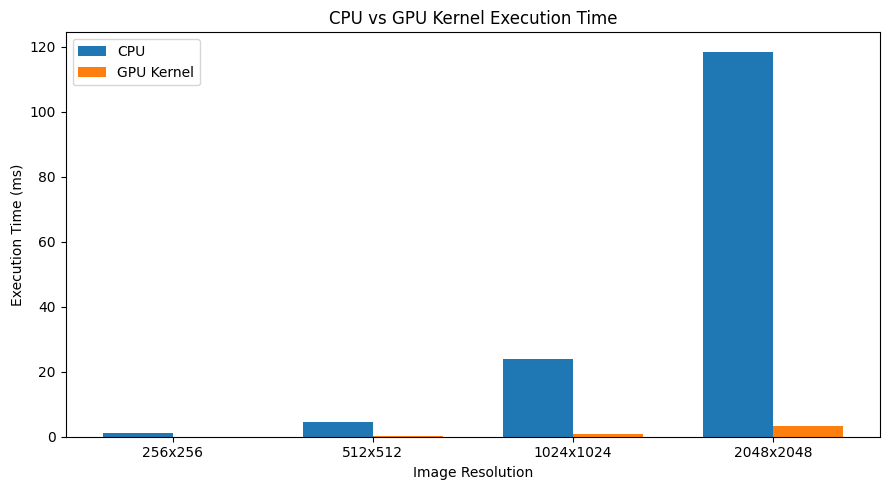

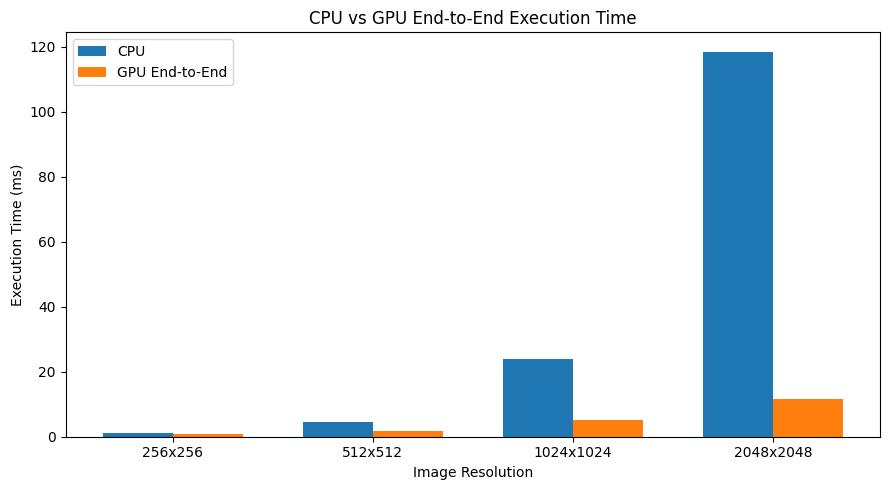

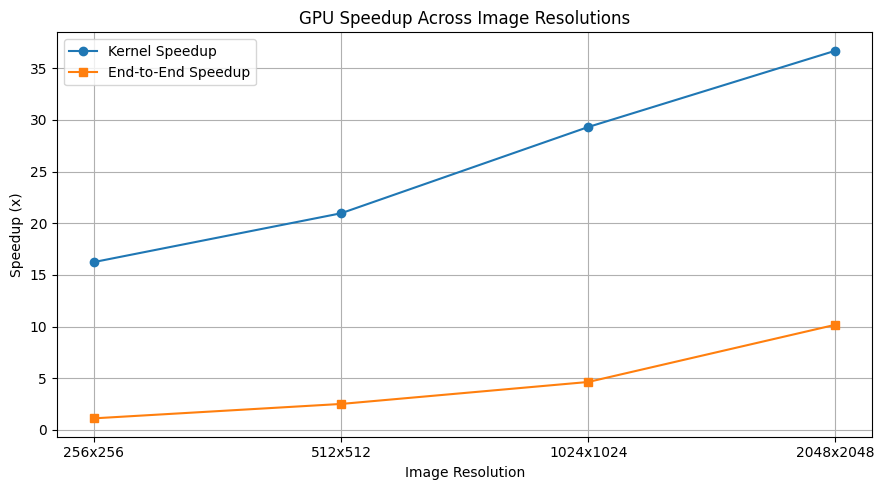

Performance graphs saved in results/figures/


In [11]:
os.makedirs("results/figures", exist_ok=True)

x = np.arange(len(results_df))
labels = results_df["Resolution"]
bar_width = 0.35

# CPU vs GPU kernel execution time
plt.figure(figsize=(9, 5))
plt.bar(x - bar_width/2, results_df["CPU (ms)"], bar_width, label="CPU")
plt.bar(x + bar_width/2, results_df["GPU Kernel (ms)"], bar_width,
        label="GPU Kernel")
plt.xlabel("Image Resolution")
plt.ylabel("Execution Time (ms)")
plt.title("CPU vs GPU Kernel Execution Time")
plt.xticks(x, labels)
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/sobel_cpu_vs_gpu_kernel.png",
            dpi=300, bbox_inches="tight")
plt.show()

# CPU vs GPU end-to-end execution time
plt.figure(figsize=(9, 5))
plt.bar(x - bar_width/2, results_df["CPU (ms)"], bar_width, label="CPU")
plt.bar(x + bar_width/2, results_df["GPU End-to-End (ms)"], bar_width,
        label="GPU End-to-End")
plt.xlabel("Image Resolution")
plt.ylabel("Execution Time (ms)")
plt.title("CPU vs GPU End-to-End Execution Time")
plt.xticks(x, labels)
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/sobel_cpu_vs_gpu_end_to_end.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Kernel and end-to-end speedup
plt.figure(figsize=(9, 5))
plt.plot(labels, results_df["Kernel Speedup"], marker="o",
         label="Kernel Speedup")
plt.plot(labels, results_df["End-to-End Speedup"], marker="s",
         label="End-to-End Speedup")
plt.xlabel("Image Resolution")
plt.ylabel("Speedup (x)")
plt.title("GPU Speedup Across Image Resolutions")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("results/figures/sobel_gpu_speedup_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Performance graphs saved in results/figures/")

## 10. GPU Resource Utilization and Memory Monitoring

The GPU is monitored while the 2048 × 2048 Sobel workload is executed repeatedly. Measurements include GPU utilization, memory usage, and power draw.

The monitoring values are sampled periodically using `nvidia-smi`. They are sampled observations, not continuous measurements.

In [12]:
# Use the same in-notebook GPU implementation; no external sobel.py is required.
monitor_image = np.random.default_rng(42).integers(
    0, 256, size=(2048, 2048), dtype=np.uint8
)

# Warm-up before monitoring
sobel_gpu(monitor_image)
cuda.synchronize()

measurements = []
stop_monitoring = threading.Event()

def monitor_gpu():
    while not stop_monitoring.is_set():
        try:
            result = subprocess.run(
                [
                    "nvidia-smi",
                    "--query-gpu=utilization.gpu,memory.used,memory.total,power.draw",
                    "--format=csv,noheader,nounits"
                ],
                capture_output=True,
                text=True,
                timeout=2
            )

            if result.returncode == 0 and result.stdout.strip():
                values = [v.strip() for v in result.stdout.strip().split(",")]
                measurements.append({
                    "GPU Utilization (%)": float(values[0]),
                    "Memory Used (MB)": float(values[1]),
                    "Total Memory (MB)": float(values[2]),
                    "Power Usage (W)": (
                        float(values[3])
                        if values[3] not in ["N/A", "[N/A]"] else np.nan
                    )
                })
        except Exception:
            pass

        stop_monitoring.wait(0.1)


monitor_thread = threading.Thread(target=monitor_gpu)
monitor_thread.start()

start_time = time.perf_counter()

for _ in range(100):
    monitor_output = sobel_gpu(monitor_image)

cuda.synchronize()
workload_time = time.perf_counter() - start_time

stop_monitoring.set()
monitor_thread.join()

df_active = pd.DataFrame(measurements)

print("Image resolution:", monitor_image.shape)
print("Number of Sobel executions:", 100)
print("Workload execution time:", round(workload_time, 3), "seconds")
print("Number of monitoring samples:", len(df_active))

if df_active.empty:
    print("No GPU monitoring samples were collected.")
else:
    display(df_active.describe().round(2))

Image resolution: (2048, 2048)
Number of Sobel executions: 100
Workload execution time: 2.438 seconds
Number of monitoring samples: 14


,GPU Utilization (%),Memory Used (MB),Total Memory (MB),Power Usage (W)
count,14.00,14.00,14.0,14.00
mean,27.07,328.43,15360.0,29.26
std,10.00,62.58,0.0,0.60
min,0.00,237.00,15360.0,28.33
25%,26.25,269.00,15360.0,28.80
50%,29.50,341.00,15360.0,29.22
75%,31.75,365.00,15360.0,29.58
max,39.00,429.00,15360.0,30.50


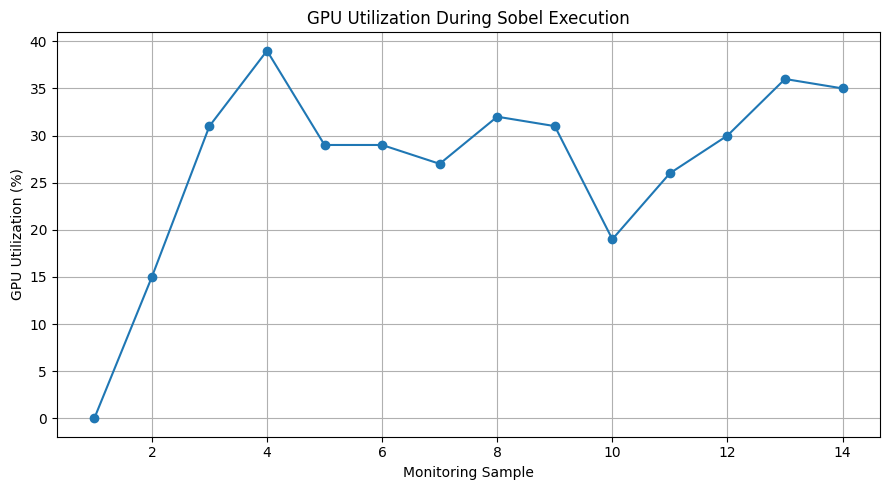

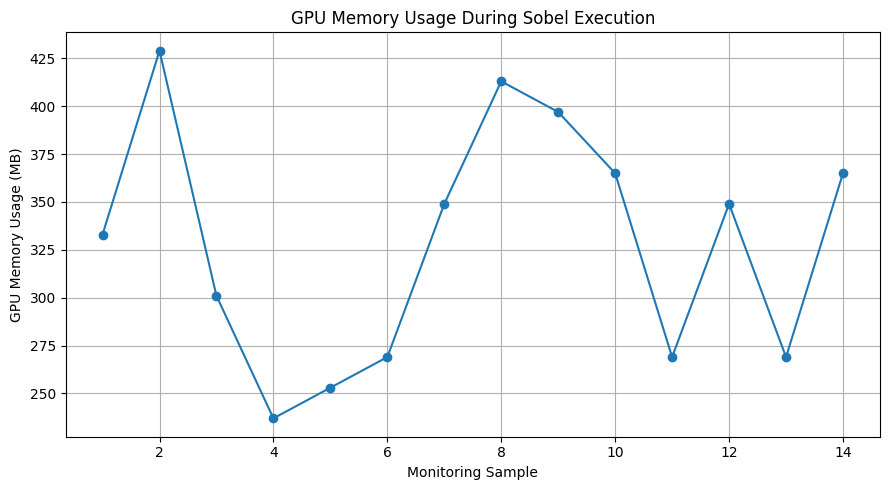

GPU resource monitoring graphs saved successfully.


In [13]:
if not df_active.empty:
    os.makedirs("results/figures", exist_ok=True)

    # GPU utilization
    plt.figure(figsize=(9, 5))
    plt.plot(range(1, len(df_active) + 1),
             df_active["GPU Utilization (%)"], marker="o")
    plt.xlabel("Monitoring Sample")
    plt.ylabel("GPU Utilization (%)")
    plt.title("GPU Utilization During Sobel Execution")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("results/figures/sobel_gpu_utilization_monitoring.png",
                dpi=300, bbox_inches="tight")
    plt.show()

    # GPU memory usage
    plt.figure(figsize=(9, 5))
    plt.plot(range(1, len(df_active) + 1),
             df_active["Memory Used (MB)"], marker="o")
    plt.xlabel("Monitoring Sample")
    plt.ylabel("GPU Memory Usage (MB)")
    plt.title("GPU Memory Usage During Sobel Execution")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("results/figures/sobel_gpu_memory_monitoring.png",
                dpi=300, bbox_inches="tight")
    plt.show()

    print("GPU resource monitoring graphs saved successfully.")
else:
    print("No files were saved because no monitoring samples were collected.")

## 11. Results and Discussion

The Sobel edge detection workload was implemented using both CPU and GPU approaches and evaluated on an NVIDIA Tesla T4 GPU through Google Colab.

### 11.1 CPU and GPU Performance

The CPU and GPU implementations were evaluated at four image resolutions: 256×256, 512×512, 1024×1024, and 2048×2048.

All four resolutions produced matching CPU and GPU outputs, with a maximum absolute difference of 0.0.

The GPU implementation achieved lower kernel execution times than the CPU implementation across all tested resolutions.

The measured kernel speedup ranged from approximately 16.24× to 36.69×.

End-to-end performance also depended on memory allocation and data transfer overhead. The GPU achieved an end-to-end speedup of approximately 1.12× for the 256×256 image, increasing to approximately 10.18× for the 2048×2048 image.

These results demonstrate that GPU acceleration becomes more beneficial as the computational workload increases.

### 11.2 GPU Memory Transfer

Host-to-Device (H2D) and Device-to-Host (D2H) transfer times were measured separately using a 2048×2048 image.

The average H2D transfer time was 9.5454 ms, while the average D2H transfer time was 9.79993 ms.

These measurements demonstrate that data movement contributes to the overall execution overhead of GPU applications.

### 11.3 Thread-Block Configuration

Three thread-block configurations were evaluated: 8×8, 16×16, and 32×32.

The measured GPU kernel times were:

- 8×8: 0.21389 ms
- 16×16: 0.22871 ms
- 32×32: 0.23253 ms

The 8×8 configuration achieved the lowest measured execution time among the tested configurations.

The 32×32 configuration was slightly slower, indicating that a larger thread block does not necessarily provide better performance for every workload.

### 11.4 Shared-Memory Optimization

The shared-memory implementation was evaluated against the baseline Sobel GPU kernel using a 2048×2048 image.

Both implementations produced identical outputs, with a maximum absolute difference of 0.0.

The measured kernel execution times were:

- Baseline kernel: 3.22748 ms
- Shared-memory kernel: 1.80614 ms

The shared-memory implementation achieved a speedup of approximately 1.787× over the baseline implementation.

This demonstrates that shared-memory optimization improved the performance of the Sobel workload in the selected GPU configuration.

### 11.5 GPU Resource Utilization

GPU resource utilization was monitored while executing the Sobel workload 100 times on a 2048×2048 image.

The monitoring results were:

- Average GPU utilization: 27.07%
- Average GPU memory usage: 328.43 MB
- Total GPU memory: 15360 MB
- Average power usage: 29.26 W
- Workload execution time: 2.438 seconds
- Number of monitoring samples: 14

These measurements provide an indication of the computational and memory requirements of the Sobel workload on the cloud GPU environment.

### 11.6 Overall Observations

The experiments demonstrate that:

1. GPU acceleration significantly reduces kernel execution time compared with CPU execution.
2. End-to-end performance depends on workload size and data transfer overhead.
3. Thread-block configuration influences GPU execution performance.
4. Shared-memory optimization improved kernel performance by approximately 1.787× compared with the baseline implementation.
5. GPU utilization and memory consumption provide additional insight into resource requirements.

Overall, the results demonstrate the benefits of GPU acceleration for image-processing workloads while highlighting the importance of evaluating kernel performance, memory transfers, optimization techniques, and resource utilization together.

## 12. Experimental Limitations

- The experiments were conducted using an NVIDIA Tesla T4 GPU in Google Colab with CUDA 13.0. Results may vary with different GPU models, drivers and execution environments.
- Execution times may vary due to GPU workload, clock frequency, runtime conditions and measurement overhead.
- The resource-monitoring experiment collected 14 samples during a short execution period. Therefore, the measurements may not capture all GPU utilization fluctuations throughout longer workloads.
- Thread-block configurations were evaluated using 8×8, 16×16 and 32×32 blocks. Other configurations may produce different results.
- Shared-memory optimization was evaluated for the selected Sobel workload and GPU configuration. Its performance benefits may differ for other image sizes, workloads and hardware.
- GPU memory-transfer overhead affects overall execution time, particularly for smaller images, where data transfer can reduce the benefits of GPU acceleration.

## 13. Conclusion

The Sobel edge detection workload was successfully implemented using both CPU and GPU approaches and evaluated on a cloud-based NVIDIA Tesla T4 GPU.

The experiments demonstrated that GPU acceleration significantly reduced kernel execution time, achieving speedups ranging from 16.24× to 36.69× across the tested image resolutions. The end-to-end speedup ranged from 1.12× to 10.18×, showing that data transfer overhead influences the overall performance, particularly for smaller images.

The thread-block comparison showed that the 8×8 configuration achieved the lowest kernel execution time among the tested configurations. Furthermore, the shared-memory implementation reduced kernel execution time from 3.22748 ms to 1.80614 ms, achieving a speedup of approximately 1.787× compared with the baseline implementation.

GPU resource monitoring provided additional insight into resource consumption during execution, with an average GPU utilization of 27.07%, memory usage of 328.43 MB and power consumption of 29.26 W.

Overall, the results demonstrate that GPU acceleration and suitable optimization techniques can significantly improve the performance of computationally intensive image-processing workloads. However, the benefits depend on image resolution, memory-transfer overhead, optimization strategy and GPU configuration.